# Section 5.2: an $\mathrm{O}(3)$-equivariant flow on $\mathbb R^4$

This notebook regenerates every number that Section 5.2 of the paper and its appendix state for the orthogonal flow, and every panel of the figures `fig:o3`, `fig:appendix-o3-flow`, `fig:appendix-o3-comparison` and the $\mathrm O(3)$ part of `fig:appendix-notebook-preimages`. Each code cell calls functions of `morsegraphs/o3_flow.py` or `morsegraphs/plotting.py` and shows one table, one line or one figure.

The flow of $\dot a=a(1-a^2)$, $\dot v=(1-2a^2-\|v\|^2)v$ on $\mathbb R\times\mathbb R^3$ is equivariant under $(a,v)\mapsto(a,Qv)$, $Q\in\mathrm O(3)$, the set $X=[-3/2,3/2]\times B^3_{3/2}$ is forward invariant, and $F$ is the time-$\log3$ map of the flow on $X$. The coordinates $(a,r)=(a,\|v\|)$ identify $X/G$ with the rectangle $[-3/2,3/2]\times[0,3/2]$. The repelling origin $O$ connects to the image $(0,1)$ of the saddle sphere $C=\{a=0,\ \|v\|=1\}$, which connects to the sinks $A_\pm=(\pm1,0)$.

## Settings

This is the only cell to edit. With `MODE = "replay"` the notebook loads the selected fit of `data/ex2_o3_flow/models/` and checks every result against `data/ex2_o3_flow/reference/results.json`, stopping at a difference. With `MODE = "train"` it retrains the selected seed with `data/ex2_o3_flow/config.json` on the CPU, which adds about 30 minutes, compares the weights with the stored ones, and reports differences instead of stopping. With `OUT = None` the results go to a new folder under `outputs/notebooks/`. A replay takes about two minutes. The device is set once per kernel, before JAX starts.

In [1]:
MODE = "replay"  # "replay": the selected fit; "train": retrain the selected seed with config.json
OUT = None       # None: a new folder under outputs/notebooks/

from morsegraphs import device
device.configure("float64", "cpu")
from morsegraphs import plotting, o3_flow

run = o3_flow.start(MODE, OUT)
run

Setting,Value
Mode,replay of the selected fit
Selected fit,"seed1, lowest validation objective (data/ex2_o3_flow/selection.json)"
Grid of the learned maps,"2^6 x 2^6 cells of Z = [-2, 2] x [0, 2]"
Data map,"pairs (E(x), f(E(x))) for 1025^2 + 4 section points; cells without samples map outside Z"
Sampled image hulls,"5 x 5 samples per cell, padding 1e-09, cut at u_2 = 0"
Reference grid,"2^6 x 2^6 cells of X/G = [-1.5, 1.5] x [0, 1.5]"
Output folder,outputs/notebooks/ex2_o3_flow-replay-20261114-014835


## The system and the reference quotient map

In the coordinates $(a,r)$, with $D=1+8a^2$, the quotient map is $\overline F(a,r)=(3a/\sqrt D,\ 3r/\sqrt{D(D+8r^2)})$. Its first coordinate increases with $a$ and its second increases with $r$ and decreases with $|a|$, so the image of a cell is enclosed by the values at its corners, and each value is enclosed by binary64 neighbors of an exact square root, found by comparing rational squares. The table checks the equivariance of $F$, that $F$ descends to $\overline F$, the closed form against an independent integration of the vector field, and the enclosures.

In [2]:
o3_flow.system_table()

Check,Value
"Equivariance of F: max |F(a, Qv) - (F_1, Q F_2)(a, v)|, 256 states, a rotation and a reflection",3.33e-16
"Quotient map: max |(a, |v|) o F - olF o (a, |v|)| on the same states",2.22e-16
"Closed form against DOP853 on the vector field, 64 states: one step, ten steps","6.16e-13, 1.49e-10"
"olF fixes O, C, A- and A+",yes
Enclosures on 2^6 x 2^6 cells of X/G contain olF of 5 x 5 points of each cell (to 1e-15),yes
Widest enclosure on that grid,0.1394


## Reference Morse graph

On the uniform grid of $2^6\times2^6$ cells of $X/G$, CMGDB computes the outer approximation of $\overline F$ from these enclosures, its Morse sets, the Morse graph and the Conley index of each Morse set over $\mathbb F_5$. An annotation lists the index map in degrees 0, 1 and 2 by its shift class: `x-1` is $\mathbb F_5$ with the identity map and `0` the zero group. Each Morse set takes the role of the equilibrium of $\overline F$ nearest to its cells, within four cells.

In [3]:
reference = o3_flow.reference_graph(run.settings["analysis"]["primary_depth"])
o3_flow.graph_table(reference, "(a, r)", "Reference Morse graph of olF")

Morse set,Role,Cells,"Box in (a, r)",Conley index,Edges to
3,O,"1984, 2048","[-0.04688, 0.04688] x [0, 0.02344]","(0, 0, 0)",2 (C)
2,C,"2026, 2090","[-0.04688, 0.04688] x [0.9844, 1.008]","(0, x-1, 0)","0 (A-), 1 (A+)"
0,A-,640,"[-1.031, -0.9844] x [0, 0.02344]","(x-1, 0, 0)",none
1,A+,3392,"[0.9844, 1.031] x [0, 0.02344]","(x-1, 0, 0)",none


## Data

The data are orbits $x, F(x), \dots, F^{10}(x)$ from the closed form of $F$. The starts have uniform $a$, $r$ and direction of $v$, with one eighth near $a=0$, one eighth near $r=0$, a quarter near the four equilibrium orbits, starts on the axes, and the four equilibrium orbits. Training uses the pairs at times $0$ and $\log3$; the later states serve only the held-out errors. The arrays are checked against the checksums recorded with them.

In [4]:
data = o3_flow.load_data(run.data)
o3_flow.data_table(data, run.data)

Split,Starts,Share with |a| < 0.1,Share with |v| < 0.1,Times
train,16384,0.306,0.367,"0, tau, ..., 10 tau"
validation,4096,0.307,0.374,"0, tau, ..., 10 tau"
test,4096,0.303,0.373,"0, tau, ..., 10 tau"


## Fits and selection

The invariant encoder $E\colon X\to Z=[-2,2]\times[0,2]$, the orbit decoder $d\colon Z\to X/G$ and the time-$\log3$ map $f$ of $Z$ are gain corrections around the orbit coordinates, each by an $\mathrm O(3)$ EMLP with two hidden layers of width 32: $E(x)=(a,\|v\|)\odot\exp(0.2\tanh e(x/1.5))$, $d(u)=u\odot\exp(0.35\tanh A(u/2))$ clipped to $X/G$, and $f(u)=2\tanh(u\odot\exp(3\tanh B(u/2))/2)$, with coordinatewise products. So $E$ is invariant, and $f$ and $d$ keep the sign of each coordinate and the axes $u_1=0$ and $u_2=0$. The objective sums the orbit reconstruction of $d(E(x))$, the orbit prediction of $d(f(E(x)))$ against $F(x)$ and the consistency of $f(E(x))$ with $E(F(x))$ (`o3_flow.loss_parts`). Five seeds were trained with 20,000 Adam updates each, and the fit with the lowest validation objective is selected before any CMGDB computation. All five fits are kept in `data/ex2_o3_flow/models/`.

In [5]:
o3_flow.seeds_table(run)

Rank,Fit,Validation objective,Selected step,One-step orbit RMS,Ten-step orbit RMS,Largest one-step residual,Least singular value of DE,Fixed points of f on the axes
1,seed1 (selected),5.354e-05,19900,0.005312,0.01797,0.01919,0.819,4
2,seed0,5.991e-05,20000,0.005684,0.02039,0.02158,0.819,4
3,seed4,7.096e-05,19900,0.006175,0.02008,0.02112,0.819,4
4,seed3,7.715e-05,19900,0.006468,0.0192,0.02289,0.819,4
5,seed2,0.0001013,19800,0.00738,0.01748,0.02576,0.819,4


The selected fit. In replay its weights are loaded. In train mode the same seed is trained again with the same data and settings, and its weights are compared with the stored ones.

In [6]:
model, fit = o3_flow.selected_fit(run, data)
fit

Loaded seed1 from data/ex2_o3_flow/models/seed1: selected at step 19,900 with validation objective 5.35414e-05; weights digest 81c34196a47b5b63.

## Held-out errors

On the 4,096 starts of the test split, the decoded prediction $d(f^h(E(x)))$ is compared with the orbit $(a,\|v\|)$ of $F^h(x)$. Section 5.2 quotes the one-step root-mean-square error. The other rows are sampled checks: the invariance of $E$, the one-step residual $|f(E(x))-E(F(x))|$, the derivative of $E$ on the section $(a,r,0,0)$, the codes of the four equilibrium orbits, and the fixed points of $f$ on the axes with their decoded orbits.

In [7]:
metrics = o3_flow.diagnostics(model, data)
o3_flow.diagnostics_table(metrics)

Quantity,RMS or value,Maximum or second value
"Orbit error |d(f^0(E(x))) - (a, |v|)(F^0(x))|",9.925e-05,0.0006378
"Orbit error |d(f^1(E(x))) - (a, |v|)(F^1(x))|",0.005312,0.02334
"Orbit error |d(f^10(E(x))) - (a, |v|)(F^10(x))|",0.01797,0.2997
"Invariance of E: max |E(a, Qv) - E(a, v)|, a rotation and a reflection",6.66e-16,
One-step residual |f(E(x)) - E(F(x))|,0.004578,0.01919
Least singular value of DE on the section; range of det DE,0.819,1.0003 to 1.0015
E(O) and |f(E(O)) - E(O)|,"(0.0000, 0.0000)",0
E(C) and |f(E(C)) - E(C)|,"(0.0000, 0.8196)",0.00114
E(A-) and |f(E(A-)) - E(A-)|,"(-1.2204, 0.0000)",0.000227
E(A+) and |f(E(A+)) - E(A+)|,"(1.2212, 0.0000)",0.000925


## Learned Morse graphs

CMGDB computes two outer approximations of $f$ on $2^6\times2^6$ cells of $Z$. The first is the map from data of Section 5.2: the pairs $(E(x),f(E(x)))$ for the representatives $x=(a,r,0,0)$ of a uniform grid of $1025\times1025$ points of $X/G$ and the four equilibrium orbits; a cell maps to the hull of the images of the samples it contains, and a cell without samples maps outside $Z$. A Morse set takes the role of the code $E$ of the equilibrium orbit nearest to its cells, within four cells.

In [8]:
data_map, _ = o3_flow.learned_graph(model, run.settings)
o3_flow.graph_table(data_map, "u", "Morse graph of the data map of f")

Morse set,Role,Cells,Box in u,Conley index,Edges to
3,O,"1984, 2048","[-0.0625, 0.0625] x [0, 0.03125]","(0, 0, 0)",2 (C)
2,C,"2009, 2010, 2073, 2074","[-0.0625, 0.0625] x [0.7812, 0.8438]",none,"0 (A-), 1 (A+)"
0,A-,768,"[-1.25, -1.188] x [0, 0.03125]","(x-1, 0, 0)",none
1,A+,3264,"[1.188, 1.25] x [0, 0.03125]","(x-1, 0, 0)",none


CMGDB returns no index at $C$ for the data map. The second outer approximation, which the quotient graph of `fig:o3` uses, has the sampled image hulls of $f$: the hull of the images of $5\times5$ points of each cell, corners included, padded by $10^{-9}$, rounded outward and cut at $u_2=0$, which $f$ preserves. These hulls are sampled, not validated enclosures.

In [9]:
hull, merged = o3_flow.learned_hull_graph(model, run.settings)
o3_flow.graph_table(hull, "u", "Morse graph of the sampled image hulls of f")

Morse set,Role,Cells,Box in u,Conley index,Edges to
3,O,"1984, 2048","[-0.0625, 0.0625] x [0, 0.03125]","(0, 0, 0)",2 (C)
2,C,"2009, 2010, 2073, 2074","[-0.0625, 0.0625] x [0.7812, 0.8438]","(0, x-1, 0)","0 (A-), 1 (A+)"
0,A-,768,"[-1.25, -1.188] x [0, 0.03125]","(x-1, 0, 0)",none
1,A+,3264,"[1.188, 1.25] x [0, 0.03125]","(x-1, 0, 0)",none


As the example prescribes, the Morse sets of one role are merged with all cells on paths between them, the group is checked to be order convex, and CMGDB recomputes the Conley index of the merged set. For the selected fit each role has one Morse set, so the merged graph has the same Morse sets as the raw graph.

In [10]:
o3_flow.graph_table(merged, "u", "Merged Morse graph of the sampled image hulls of f")

Morse set,Role,Merged Morse sets,Cells,Box in u,Conley index,Edges to
3,O,3,"1984, 2048","[-0.0625, 0.0625] x [0, 0.03125]","(0, 0, 0)",2 (C)
2,C,2,"2009, 2010, 2073, 2074","[-0.0625, 0.0625] x [0.7812, 0.8438]","(0, x-1, 0)","0 (A-), 1 (A+)"
0,A-,0,768,"[-1.25, -1.188] x [0, 0.03125]","(x-1, 0, 0)",none
1,A+,1,3264,"[1.188, 1.25] x [0, 0.03125]","(x-1, 0, 0)",none


## Comparison with the reference

The learned nodes take the labels of the reference only where the graphs agree: the same roles, the same Conley index in the rectangle at each role, and the same edges between roles.

In [11]:
comparison = {"data_map": o3_flow.compare_graphs(reference, data_map), "hull": o3_flow.compare_graphs(reference, merged)}
o3_flow.comparison_table(comparison)

Role,Reference,Data map,Agree,Sampled hulls,Agree
O,"(0, 0, 0)","(0, 0, 0)",yes,"(0, 0, 0)",yes
C,"(0, x-1, 0)",none,no,"(0, x-1, 0)",yes
A-,"(x-1, 0, 0)","(x-1, 0, 0)",yes,"(x-1, 0, 0)",yes
A+,"(x-1, 0, 0)","(x-1, 0, 0)",yes,"(x-1, 0, 0)",yes
Order,"O -> C, C -> A-, C -> A+","O -> C, C -> A-, C -> A+",yes,"O -> C, C -> A-, C -> A+",yes


## Attracting regions, tolerances and residuals modulo $G$

For each minimal Morse set $\mathcal M$, $\mathcal A$ is the set of cells from which no path of the outer approximation leaves the box, reaches a cell without samples, or reaches a Morse set outside $\mathcal M$, and $N=|\mathcal A|$. The face $u_2=0$ is a face of the orbit space, not an exit. The tolerance of $N$ is the distance from the images of the cells of $\mathcal A$ to the complement of $N$. The residual modulo $G$ of $f$ at $x$ is $|f(E(x))-E(F(x))|$; it is constant on orbits, and every orbit meets the section $(a,r,0,0)$, so its maximum over $E^{-1}(N)$ is sampled on 1,152,136 section points: the centers of $1024\times1024$ cells of $X/G$, points near $a=0$, on $r=0$, and the four equilibrium orbits. A residual below the tolerance is the inequality of Proposition `prop:equivariant_pullback`(ii) for the sampled quantities, so $E^{-1}(N)$ is an observed, not proved, attracting block for $F$.

In [12]:
region_results, samples = o3_flow.attracting_regions_of(model, {"data_map": data_map, "hull": merged}, run.settings)
o3_flow.regions_table(region_results, samples, {"data_map": data_map, "hull": merged})

Map,Minimal Morse set,Cells of A,Box of |A| in u,Samples in E^-1(N),Largest residual,Tolerance,Residual below tolerance
data map,A-,1160,"[-1.875, -0.0625] x [0, 1.25]","510,659",0.01957,0.1231,yes
data map,A+,1160,"[0.0625, 1.875] x [0, 1.25]","510,659",0.01805,0.1225,yes
sampled hulls,A-,1984,"[-2, -0.0625] x [0, 2]","510,659",0.01957,0.1087,yes
sampled hulls,A+,1984,"[0.0625, 2] x [0, 2]","510,659",0.01805,0.1053,yes


## Conley indices in $X$

Theorem `thm:sphere-reconstruction` gives the index map of the lifted index pair from quotient data (Appendix `app:o3-instance`). Here $P/G=\{r=0\}$, the orbits $G/H=\mathrm O(3)/\mathrm O(2)$ of the points with $v\neq0$ are spheres $S^2$ ($m=2$) and $\delta$ is the identity (degree 1), so the index in degree $k$ is the direct sum of the quotient index in degree $k$ and the index relative to $N_P/G$ in degree $k-2$. `morsegraphs.homology` evaluates it over $\mathbb F_5$ on the index pair $(|\mathcal M\cup F(\mathcal M)|,|F(\mathcal M)\setminus\mathcal M|)$ of each Morse set, with a chain selector that maps the face $r=0$ into itself, for the reference graph and for the merged sampled-hull graph. The indices proved on explicit index pairs (Supplement `supp:o3-pairs`) are $H_4=\mathbb F$ at $O$, $H_1=H_3=\mathbb F$ at $C$ and $H_0=\mathbb F$ at $A_\pm$, with identity index maps. The reference reconstruction uses the enclosures of $\overline F$. The learned one uses sampled hulls, so its indices in $X$ are observed.

In [13]:
indices = o3_flow.reconstructed_indices({"reference": reference, "learned": merged})
o3_flow.indices_table(indices)

Role,Proved in X,Nonzero groups,Reference in X/G,Reference in X,Learned in Z,Learned in X,Agree
O,"(0, 0, 0, 0, x-1)",H_4 = F,"(0, 0, 0)","(0, 0, 0, 0, x-1)","(0, 0, 0)","(0, 0, 0, 0, x-1)",yes
C,"(0, x-1, 0, x-1, 0)",H_1 = H_3 = F,"(0, x-1, 0)","(0, x-1, 0, x-1, 0)","(0, x-1, 0)","(0, x-1, 0, x-1, 0)",yes
A-,"(x-1, 0, 0, 0, 0)",H_0 = F,"(x-1, 0, 0)","(x-1, 0, 0, 0, 0)","(x-1, 0, 0)","(x-1, 0, 0, 0, 0)",yes
A+,"(x-1, 0, 0, 0, 0)",H_0 = F,"(x-1, 0, 0)","(x-1, 0, 0, 0, 0)","(x-1, 0, 0)","(x-1, 0, 0, 0, 0)",yes


## Figures

Each panel is saved bare, with no letters, titles or legends, as PDF and SVG under `OUT/figures/`, with the file name the manuscript includes, and shown below under that name. A Morse set is colored by its role: the attractors $A_-$ blue and $A_+$ green, the saddle orbit $C$ purple and the repelling origin $O$ orange. Dark cells are Morse sets; light blue and light green cells form the attracting regions $\mathcal A$ of $A_-$ and $A_+$, and light purple cells lie on paths of the outer approximation from $O$ to $C$. The orbit coordinates are $(a,r)$ and the learned coordinates $(u_1,u_2)$.

### `fig:o3`

(a) The exact quotient flow in $(a,r)$. (b) Decoded orbits $d(f^k(E(x_0)))$, $k\le40$, of the learned map from nine representatives $x_0=(a_0,r_0,0,0)$ near $O$, with the decoded fixed points of $f$ on the latent axes, filled at the minimal Morse sets. (c) The Morse sets of the sampled-hull graph in $Z$, the attracting regions of $A_\pm$ and the cells on paths from $O$ to $C$. (d) The merged Morse graph in $Z$ with its Conley indices. (e) The same graph with the indices in $X$ reconstructed above.

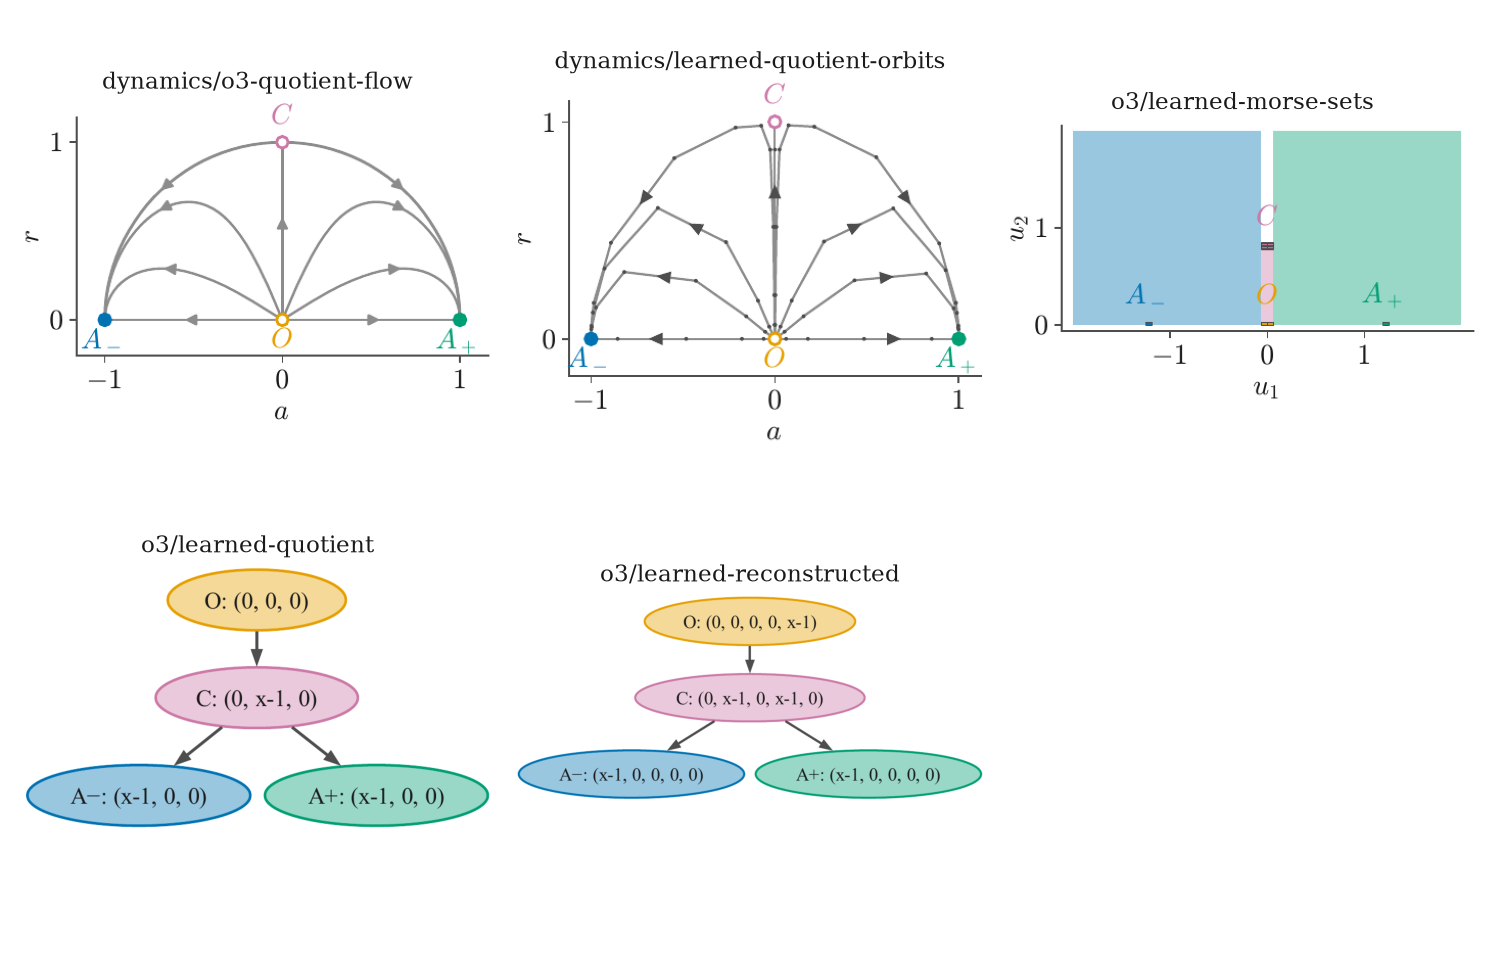

In [14]:
basins = {"reference": o3_flow.basins(reference), "hull": o3_flow.basins(merged)}
panels = o3_flow.figure_o3(model, metrics, merged, basins["hull"], indices, run.figures)
plotting.show(panels.values(), panels.keys(), columns=3)

### `fig:appendix-o3-flow`

The exact quotient flow in $(a,r)$, panel (a) of `fig:o3`. A point with $r>0$ stands for a whole spherical orbit.

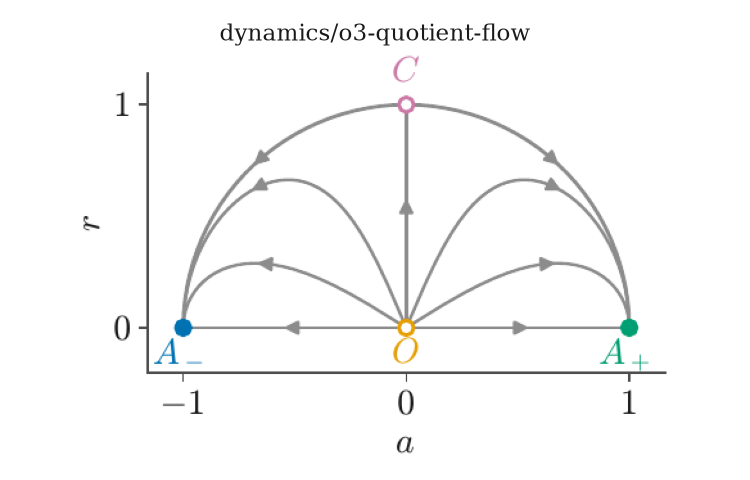

In [15]:
panels = o3_flow.figure_o3_flow(run.figures)
plotting.show(panels.values(), panels.keys(), width=5.)

### `fig:appendix-o3-comparison`

The reference $\overline F$ on $X/G$ (left) and the learned $f$ on $Z$ with sampled image hulls (right). From the top: the Morse sets with the attracting regions and the cells on paths from $O$ to $C$, the Morse graphs with their Conley indices in the rectangle, and the Morse graphs with the indices in $X$ reconstructed from them.

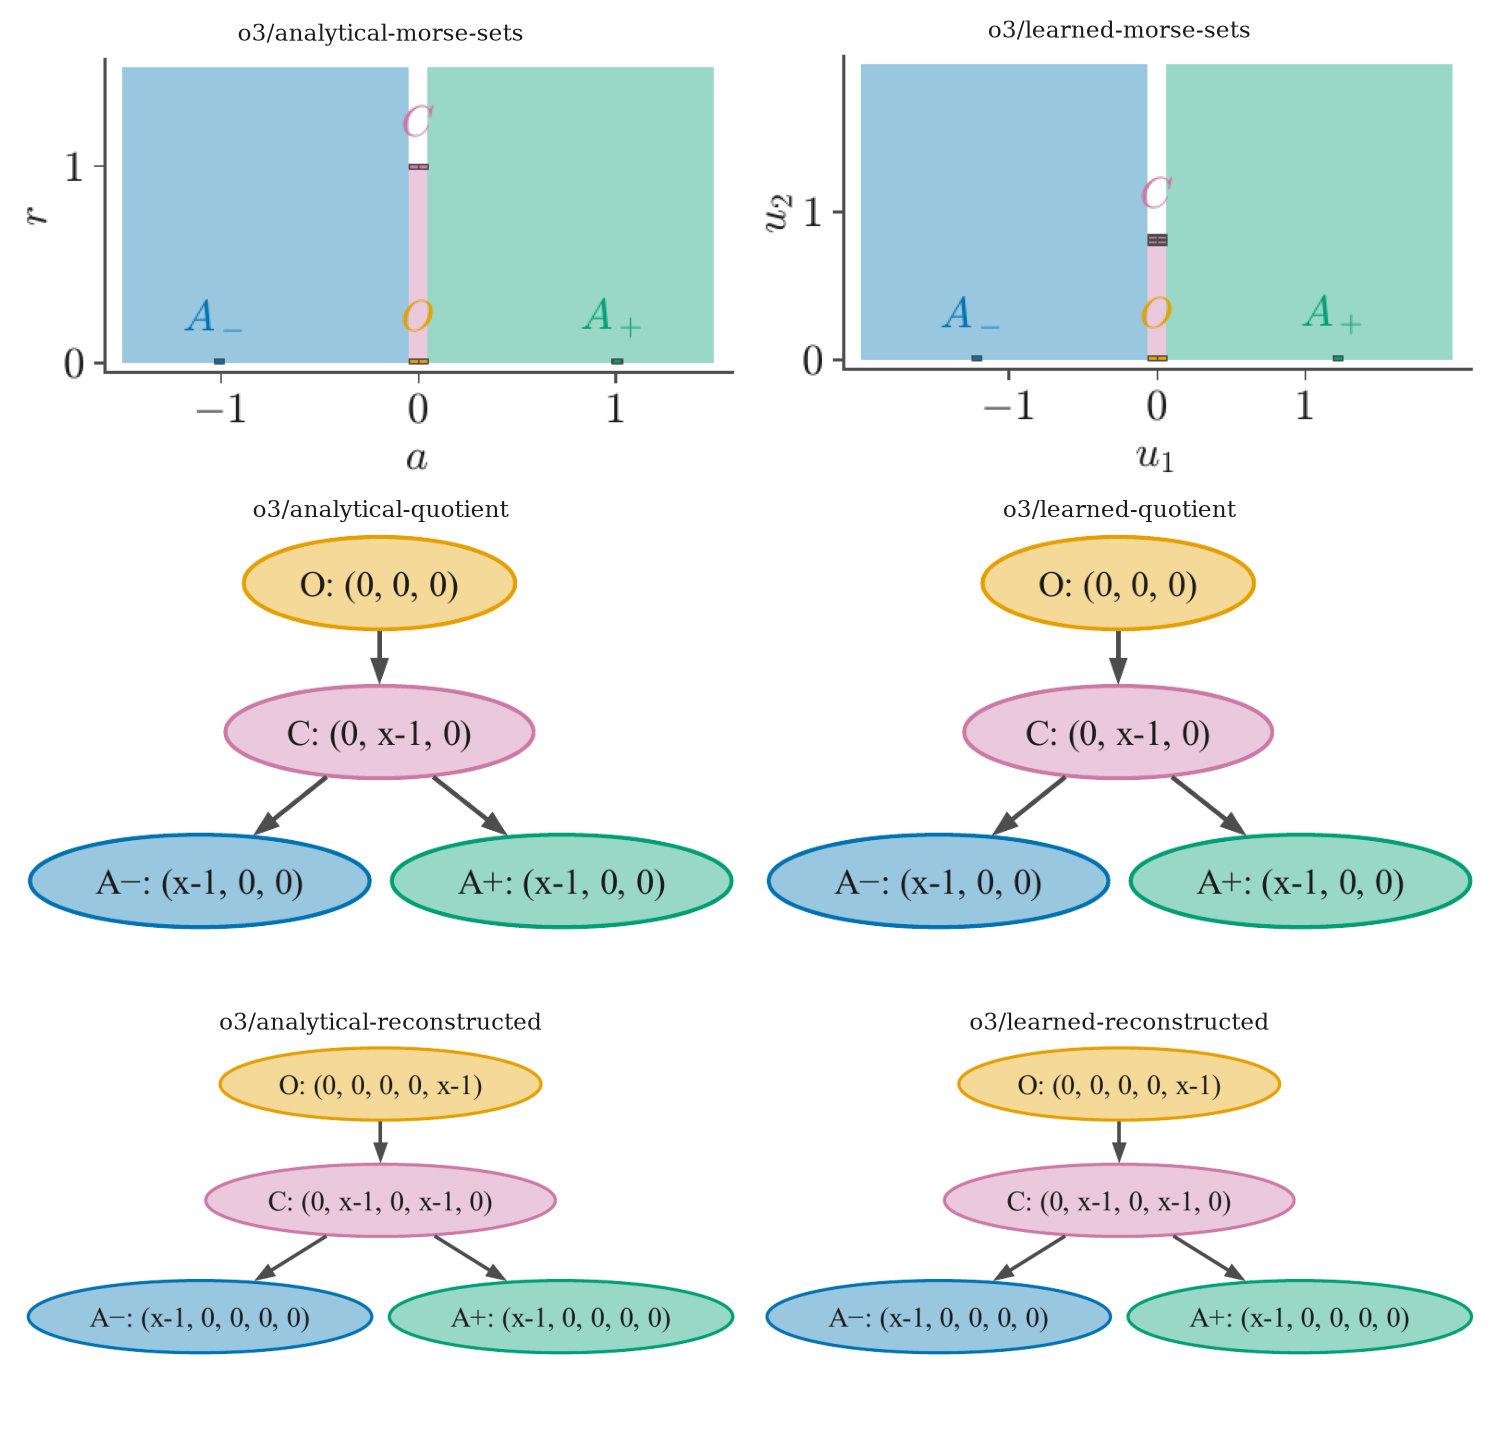

In [16]:
panels = o3_flow.figure_o3_comparison(reference, basins["reference"], merged, basins["hull"], indices, run.figures)
plotting.show(panels.values(), panels.keys(), columns=2)

### `fig:appendix-notebook-preimages`, $\mathrm O(3)$ panels

Left, the cells of $Z$ colored as in `fig:o3`(c), with the cells that contain no code $E(a,r,0,0)$ of a section point in gray. Right, for $513\times513$ representatives $(a,r,0,0)$ of $X/G$, the color of the latent cell that contains $E(a,r,0,0)$: an inverse image under the encoder, not a decoded set, in which every point $(a,r)$ stands for all $v$ with $\|v\|=r$. The graph of the grouping is drawn only when some role has several Morse sets, which is not the case for the selected fit.

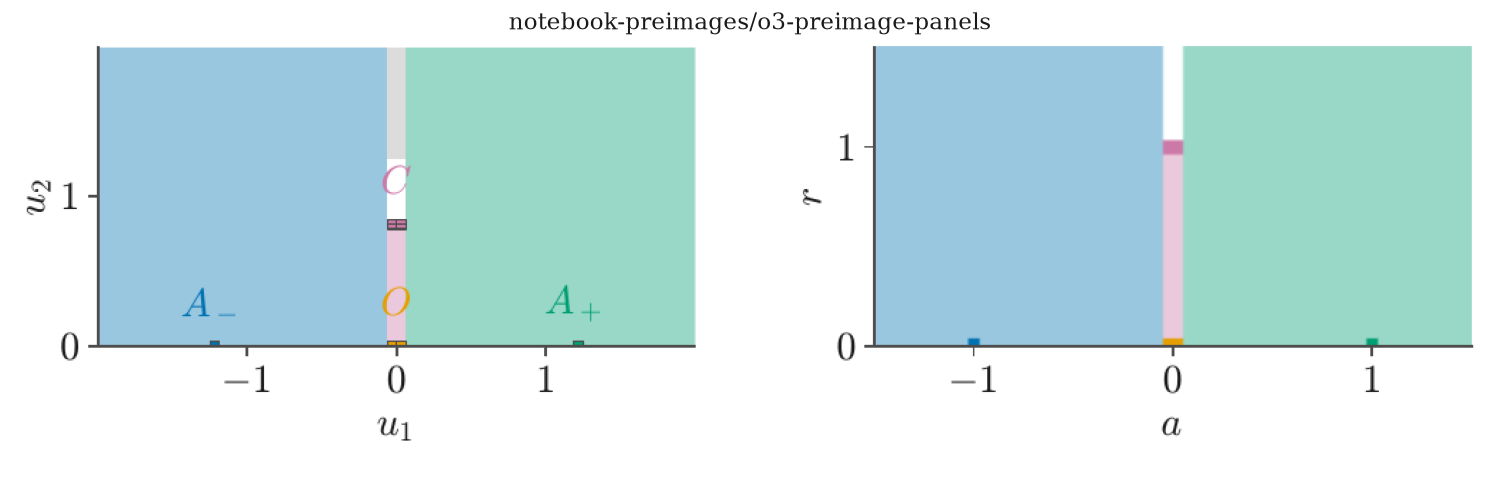

In [17]:
panels = o3_flow.figure_preimages(model, hull, merged, basins["hull"], run.figures)
plotting.show(panels.values(), panels.keys(), width=10.)

## Replay check

The record of the results above (the fit, the diagnostics, the reference, data-map, sampled-hull and merged graphs, the comparisons, the regions with their tolerances and residuals, the cells of the figure regions, and the reconstructed indices) is written to `OUT/record.json` and compared with `data/ex2_o3_flow/reference/results.json`, which `scripts/record_reference.py ex2_o3_flow` writes: graphs, regions of the figures and indices exactly, other numbers to relative tolerance $10^{-9}$. In replay a difference stops the notebook. In train mode it is reported.

In [18]:
record = o3_flow.record_of(run.fit, metrics, reference, data_map, hull, merged, region_results, samples, basins, indices)
check = o3_flow.check_record(run, record)
check

The record matches data/ex2_o3_flow/reference/results.json: 17,306 values, graphs, basins and indices exactly, other numbers to relative 1e-9.

## Summary

Every quantity that Section 5.2 and its appendix state, computed here, next to the value in the current text of the manuscript. The text describes earlier fits in places, so some of its values differ from those of the selected fit; the comparison is informational. The table is also written, with the replay check, the list of saved panels and the package versions, to `OUT/verification.json`.

In [19]:
o3_flow.summary(run, record, check)

Where,Statement,Manuscript,Computed
Section 5.2,One-step orbit RMS on held-out data,0.0053,0.0053
Section 5.2,"Data-map and reference Morse graphs on 2^6 x 2^6 cells agree, order O -> C -> A-+","agree, O -> C -> A-+","same order (O -> C, C -> A-, C -> A+); indices agree at O and A-+: yes; index at C: none"
Section 5.2,Quotient graph of fig:o3 from sampled image hulls: native Morse sets and nodes,6 grouped into 4 (a separate fit),"4 Morse sets, 4 nodes, of the selected fit, no grouping"
Section 5.2,"Sampled-hull indices agree with the reference, (0, x-1, 0) at C",yes,"yes, (0, x-1, 0) at C"
Section 5.2,A-: largest sampled residual of the data-map fit against the tolerance,0.020 < 0.123,0.0196 < 0.123
Section 5.2,A+: largest sampled residual of the data-map fit against the tolerance,0.018 < 0.122,0.018 < 0.122
Section 5.2,"Indices in X: H_4 = F at O, H_1 = H_3 = F at C, H_0 = F at A-+",proved,reconstruction agrees for the reference and the learned graph
supp:o3-computation,Cells of each attracting region of the data map,"1,160","1,160 and 1,160"
supp:o3-computation,Encoded physical sources of the data map,1025^2 + 4,1025^2 + 4
supp:o3-computation,"A-: (tolerance, residual)","(0.123087, 0.0195666)","(0.123087, 0.0195666)"
